# T03 · EDA: visão geral, alvo e qualidade dos dados

**Objetivo:** dar ao time e ao relatório o retrato geral do dataset: tamanho, balanceamento do alvo e
problemas de qualidade que precisam de tratamento (limpeza da T08).

**Como ler:** cada gráfico tem, logo abaixo, uma interpretação gerada a partir dos próprios dados
(nenhum número fixo no texto). As figuras são salvas em `results/figures/` com o prefixo `t03_`.

**Escopo:** este notebook é o panorama geral. Os detalhes de cada grupo de variáveis ficam nos notebooks
da T04 (idade, sexo, altura, peso e IMC), T05 (pressão), T06 (colesterol, glicose e hábitos) e T07 (correlação).

**Dados:** a EDA usa o dado **bruto** (`load_raw`), como veio do CSV. Só na seção 6 aparece o efeito da limpeza.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from cardio.config import DATA_PATH, FIGURES_DIR, PLAUSIBLE_RANGES, PRESSURE_RANGES, TARGET
from cardio.data.loader import load_dataset, load_raw
from cardio.data.preprocessing import clean

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = {0: "Sem doença", 1: "Com doença"}


def salvar(fig, nome: str) -> None:
    """Salva a figura em results/figures/ com o prefixo da tarefa."""
    fig.savefig(FIGURES_DIR / f"t03_{nome}.png", dpi=120, bbox_inches="tight")


def pct(valor: float, casas: int = 0) -> str:
    """Formata uma proporção (0–1) como porcentagem no padrão brasileiro: 0.497 -> '49,7%'."""
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    """Formata um número com vírgula decimal: 0.238 -> '0,24'."""
    return f"{valor:.{casas}f}".replace(".", ",")


def inteiro(valor: int) -> str:
    """Formata um inteiro com ponto de milhar: 68588 -> '68.588'."""
    return f"{int(valor):,}".replace(",", ".")


def texto(conteudo: str) -> None:
    """Mostra um texto de interpretação formatado em Markdown."""
    display(Markdown(conteudo))

## 1. Dimensões, tipos e estatísticas descritivas

In [2]:
df = load_raw(DATA_PATH)
print(f"{inteiro(len(df))} pacientes, {df.shape[1]} colunas\n")
df.info()

70.000 pacientes, 13 colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [3]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.4,28851.3,0.0,25006.8,50001.5,74889.2,99999.0
age,70000.0,19468.9,2467.3,10798.0,17664.0,19703.0,21327.0,23713.0
gender,70000.0,1.3,0.5,1.0,1.0,1.0,2.0,2.0
height,70000.0,164.4,8.2,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.2,14.4,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.8,154.0,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.6,188.5,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,1.4,0.7,1.0,1.0,1.0,2.0,3.0
gluc,70000.0,1.2,0.6,1.0,1.0,1.0,1.0,3.0
smoke,70000.0,0.1,0.3,0.0,0.0,0.0,0.0,1.0


In [5]:
idade_anos = df["age"] / 365.25
mulheres = (df["gender"] == 1).mean()

texto(f"""**O que chama atenção:**

- `age` está em **dias**: vai de {inteiro(df["age"].min())} a {inteiro(df["age"].max())} dias,
  ou seja, de **{num(idade_anos.min(), 1)}** a **{num(idade_anos.max(), 1)} anos**. Precisa ser convertida para anos.
- `ap_hi` (sistólica) vai de **{inteiro(df["ap_hi"].min())}** a **{inteiro(df["ap_hi"].max())}** mmHg e `ap_lo` (diastólica)
  de **{inteiro(df["ap_lo"].min())}** a **{inteiro(df["ap_lo"].max())}** mmHg: há valores negativos e impossíveis.
- `height` vai de **{inteiro(df["height"].min())}** a **{inteiro(df["height"].max())} cm** e `weight` de
  **{num(df["weight"].min(), 0)}** a **{num(df["weight"].max(), 0)} kg**: há erros de registro nos extremos.
- `gender` usa 1 = mulher e 2 = homem; **{pct(mulheres)}** dos pacientes são mulheres, então a amostra não é equilibrada por sexo.
- `cholesterol` e `gluc` são categorias ordenadas (1, 2 e 3); `smoke`, `alco`, `active` e `cardio` são 0/1; `id` é só um identificador.
""")

**O que chama atenção:**

- `age` está em **dias**: vai de 10.798 a 23.713 dias,
  ou seja, de **29,6** a **64,9 anos**. Precisa ser convertida para anos.
- `ap_hi` (sistólica) vai de **-150** a **16.020** mmHg e `ap_lo` (diastólica)
  de **-70** a **11.000** mmHg: há valores negativos e impossíveis.
- `height` vai de **55** a **250 cm** e `weight` de
  **10** a **200 kg**: há erros de registro nos extremos.
- `gender` usa 1 = mulher e 2 = homem; **65%** dos pacientes são mulheres, então a amostra não é equilibrada por sexo.
- `cholesterol` e `gluc` são categorias ordenadas (1, 2 e 3); `smoke`, `alco`, `active` e `cardio` são 0/1; `id` é só um identificador.


## 2. Distribuição do alvo (`cardio`)

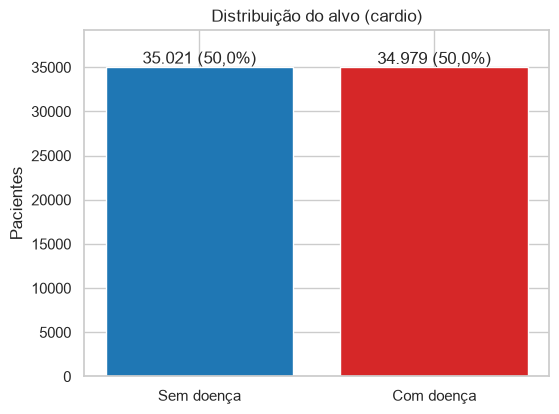

**Interpretação:** as classes estão **balanceadas**: 35.021 pacientes sem doença e
34.979 com doença (diferença de 42 pacientes, 0,1 ponto percentual).
Por isso a acurácia é uma métrica informativa e não é preciso reamostrar as classes.


In [6]:
contagem = df[TARGET].map(CLASSES).value_counts().reindex(list(CLASSES.values()))
taxa_doenca = df[TARGET].mean()

fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(contagem.index, contagem.values, color=["tab:blue", "tab:red"])
for barra, valor in zip(barras, contagem.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 400,
            f"{inteiro(valor)} ({pct(valor / len(df), 1)})", ha="center")
ax.set(title="Distribuição do alvo (cardio)", ylabel="Pacientes")
ax.set_ylim(0, contagem.max() * 1.12)

salvar(fig, "alvo")
plt.show()

diferenca = abs(contagem.iloc[0] - contagem.iloc[1])
texto(f"""**Interpretação:** as classes estão **balanceadas**: {inteiro(contagem.iloc[0])} pacientes sem doença e
{inteiro(contagem.iloc[1])} com doença (diferença de {inteiro(diferenca)} pacientes, {num(diferenca / len(df) * 100, 1)} ponto percentual).
Por isso a acurácia é uma métrica informativa e não é preciso reamostrar as classes.
""")

## 3. Valores ausentes

In [7]:
ausentes = df.isna().sum()
total_ausentes = int(ausentes.sum())
display(ausentes.to_frame("ausentes").T)

texto(f"""**Interpretação:** total de valores ausentes: **{inteiro(total_ausentes)}**.
""" + ("Nenhuma coluna tem valores ausentes, então não há imputação a fazer (a checagem fica registrada aqui)."
       if total_ausentes == 0 else "Há colunas com valores ausentes: é preciso definir como tratá-los."))

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
ausentes,0,0,0,0,0,0,0,0,0,0,0,0,0


**Interpretação:** total de valores ausentes: **0**.
Nenhuma coluna tem valores ausentes, então não há imputação a fazer (a checagem fica registrada aqui).

## 4. Duplicados

Pacientes idênticos em todas as colunas, **ignorando o `id`**. Se ficarem no dado, o mesmo paciente pode cair
no treino e no teste, o que infla o desempenho.

In [8]:
colunas_sem_id = [coluna for coluna in df.columns if coluna != "id"]
n_extras = int(df.duplicated(subset=colunas_sem_id).sum())
duplicadas = df[df.duplicated(subset=colunas_sem_id, keep=False)].sort_values(colunas_sem_id)
print(f"{inteiro(n_extras)} linhas repetem outra linha (ignorando o id); {inteiro(len(duplicadas))} registros envolvidos")
duplicadas

24 linhas repetem outra linha (ignorando o id); 48 registros envolvidos


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
6325,9004,14552,1,158,64.0,120,80,1,1,0,0,1,0
40365,57690,14552,1,158,64.0,120,80,1,1,0,0,1,0
17101,24435,16160,1,168,65.0,120,80,1,1,0,0,1,1
64169,91592,16160,1,168,65.0,120,80,1,1,0,0,1,1
1204,1685,16793,1,165,68.0,120,80,1,1,0,0,1,0
21784,31110,16793,1,165,68.0,120,80,1,1,0,0,1,0
28300,40450,16805,1,157,67.0,120,80,1,1,0,0,1,0
60474,86345,16805,1,157,67.0,120,80,1,1,0,0,1,0
10494,14974,16937,2,170,70.0,120,80,1,1,0,0,0,0
44653,63776,16937,2,170,70.0,120,80,1,1,0,0,0,0


In [9]:
texto(f"""**Interpretação:** há **{inteiro(n_extras)} linhas** que repetem outro paciente em todas as colunas, exceto o `id`
({inteiro(len(duplicadas))} registros no total, contando as originais). É uma fração pequena ({pct(n_extras / len(df), 2)} do dataset),
mas **recomenda-se removê-las**: a função `clean()` (T08) mantém a primeira ocorrência e descarta as demais.
""")

**Interpretação:** há **24 linhas** que repetem outro paciente em todas as colunas, exceto o `id`
(48 registros no total, contando as originais). É uma fração pequena (0,03% do dataset),
mas **recomenda-se removê-las**: a função `clean()` (T08) mantém a primeira ocorrência e descarta as demais.


## 5. Faixas de valores problemáticas

Resumo dos problemas de faixa (os detalhes estão nos notebooks da T04 e da T05). As faixas plausíveis vêm de
`cardio.config` e são as mesmas usadas pela limpeza.

In [10]:
bmi = df["weight"] / (df["height"] / 100) ** 2
valores = {"ap_hi": df["ap_hi"], "ap_lo": df["ap_lo"], "height": df["height"], "weight": df["weight"], "bmi": bmi}

linhas = []
for coluna, (minimo, maximo) in {**PRESSURE_RANGES, **PLAUSIBLE_RANGES}.items():
    serie = valores[coluna]
    linhas.append({
        "variável": coluna,
        "mínimo": round(float(serie.min()), 1),
        "máximo": round(float(serie.max()), 1),
        "faixa plausível": f"{minimo:g}–{maximo:g}",
        "fora da faixa": int((~serie.between(minimo, maximo)).sum()),
    })
diastolica_maior = int((df["ap_lo"] >= df["ap_hi"]).sum())
linhas.append({"variável": "ap_lo ≥ ap_hi", "mínimo": None, "máximo": None,
               "faixa plausível": "ap_lo < ap_hi", "fora da faixa": diastolica_maior})

faixas = pd.DataFrame(linhas).set_index("variável")
fora = faixas["fora da faixa"]
faixas

,mínimo,máximo,faixa plausível,fora da faixa
variável,,,,
ap_hi,-150.0,16020.0,70–250,229
ap_lo,-70.0,11000.0,40–200,1012
height,55.0,250.0,130–210,93
weight,10.0,200.0,35–200,20
bmi,3.5,298.7,15–60,93
ap_lo ≥ ap_hi,NaN,NaN,ap_lo < ap_hi,1236


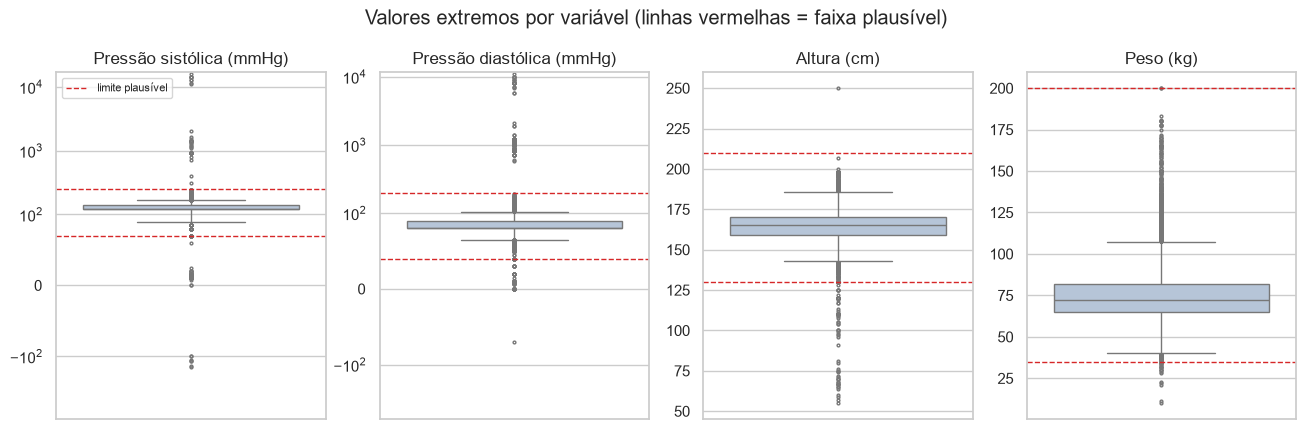

**Interpretação:** a **pressão arterial** é o problema mais grave: 229 pacientes com sistólica
e 1.012 com diastólica fora da faixa plausível (a escala dos gráficos de pressão é logarítmica,
senão os extremos esmagariam o resto), além de 1.236 com diastólica maior ou igual à sistólica.
Altura (93), peso (20) e IMC (93) também têm erros de registro,
mas em menor número. As contagens se sobrepõem: um mesmo paciente pode violar mais de uma regra.


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
grafico = [("ap_hi", "Pressão sistólica (mmHg)"), ("ap_lo", "Pressão diastólica (mmHg)"),
           ("height", "Altura (cm)"), ("weight", "Peso (kg)")]
limites = {**PRESSURE_RANGES, **PLAUSIBLE_RANGES}

for ax, (coluna, rotulo) in zip(axes, grafico):
    sns.boxplot(y=df[coluna], ax=ax, color="lightsteelblue", flierprops={"markersize": 2})
    minimo, maximo = limites[coluna]
    ax.axhline(minimo, color="tab:red", linestyle="--", linewidth=1)
    ax.axhline(maximo, color="tab:red", linestyle="--", linewidth=1, label="limite plausível")
    if coluna.startswith("ap_"):
        ax.set_yscale("symlog", linthresh=100)
    ax.set(title=rotulo, ylabel="")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Valores extremos por variável (linhas vermelhas = faixa plausível)", y=1.02)

salvar(fig, "faixas")
plt.show()

texto(f"""**Interpretação:** a **pressão arterial** é o problema mais grave: {inteiro(fora["ap_hi"])} pacientes com sistólica
e {inteiro(fora["ap_lo"])} com diastólica fora da faixa plausível (a escala dos gráficos de pressão é logarítmica,
senão os extremos esmagariam o resto), além de {inteiro(diastolica_maior)} com diastólica maior ou igual à sistólica.
Altura ({inteiro(fora["height"])}), peso ({inteiro(fora["weight"])}) e IMC ({inteiro(fora["bmi"])}) também têm erros de registro,
mas em menor número. As contagens se sobrepõem: um mesmo paciente pode violar mais de uma regra.
""")

## 6. Efeito da limpeza (T08)

`clean()` remove duplicados e registros fisiologicamente impossíveis. As regras são aplicadas em sequência, e cada uma
conta só as linhas que removeu.

,regra,linhas_removidas
0,Duplicados (ignorando o id),24
1,Sistólica fora de 70–250 mmHg,229
2,Diastólica fora de 40–200 mmHg,997
3,Diastólica >= sistólica,103
4,Altura fora de 130–210 cm,89
5,Peso fora de 35–200 kg,16
6,IMC fora de 15–60 kg/m²,33


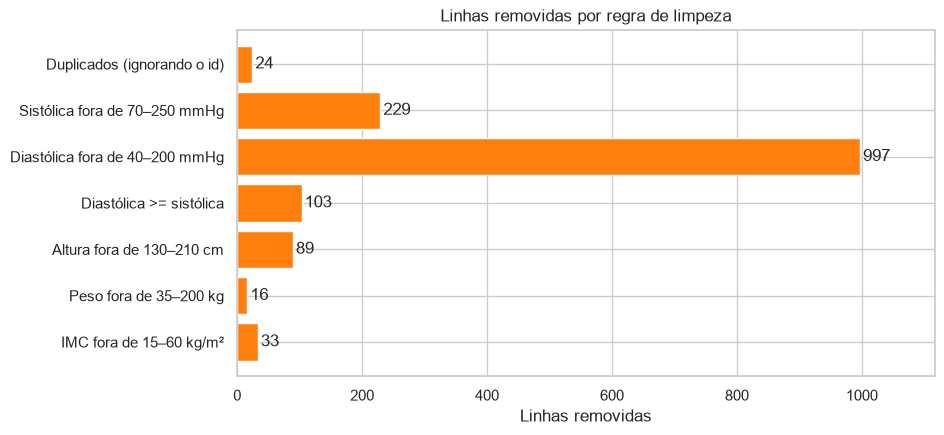

**Interpretação:** a limpeza remove **1.491 linhas** (2,1% do total) e
deixa **68.509 pacientes**. A regra que mais remove é a de **Diastólica fora de 40–200 mmHg**.
A taxa de doença muda de 49,97% para 49,49%: a limpeza não desbalanceia as classes.


In [12]:
limpo = clean(load_dataset(DATA_PATH), verbose=False)
log = limpo.attrs["cleaning_log"]
removidas = len(df) - len(limpo)
taxa_limpa = limpo[TARGET].mean()
display(log)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(log["regra"][::-1], log["linhas_removidas"][::-1], color="tab:orange")
for posicao, valor in enumerate(log["linhas_removidas"][::-1]):
    ax.text(valor + 5, posicao, inteiro(valor), va="center")
ax.set(title="Linhas removidas por regra de limpeza", xlabel="Linhas removidas")
ax.set_xlim(0, log["linhas_removidas"].max() * 1.12)

salvar(fig, "limpeza")
plt.show()

texto(f"""**Interpretação:** a limpeza remove **{inteiro(removidas)} linhas** ({pct(removidas / len(df), 1)} do total) e
deixa **{inteiro(len(limpo))} pacientes**. A regra que mais remove é a de **{log.loc[log["linhas_removidas"].idxmax(), "regra"]}**.
A taxa de doença muda de {pct(taxa_doenca, 2)} para {pct(taxa_limpa, 2)}: a limpeza não desbalanceia as classes.
""")

## 7. Tipos de variável

O Kaggle descreve três tipos de feature: **objetivas** (fatos do paciente), **de exame** (resultados de medições)
e **subjetivas** (informadas pelo próprio paciente). A distinção importa: as subjetivas são autodeclaradas e,
por isso, menos confiáveis.

In [13]:
tipos = pd.DataFrame([
    ("Objetiva", "age, gender, height, weight", "Fatos do paciente. `age` vira `age_years` e `gender` vira `sex_male` em `load_dataset`."),
    ("De exame", "ap_hi, ap_lo, cholesterol, gluc", "Resultados de medições e exames; a pressão tem os erros de registro vistos na seção 5."),
    ("Subjetiva", "smoke, alco, active", "Autodeclaradas (0/1): podem estar subestimadas ou enviesadas."),
    ("Identificador", "id", "Não é feature."),
    ("Alvo", "cardio", "1 = tem doença cardiovascular."),
], columns=["Tipo", "Variáveis", "Observação"])

colunas_descritas = [c.strip() for linha in tipos["Variáveis"] for c in linha.split(",")]
assert sorted(colunas_descritas) == sorted(df.columns), "alguma coluna ficou sem tipo"
tipos

,Tipo,Variáveis,Observação
0,Objetiva,"age, gender, height, weight",Fatos do paciente. `age` vira `age_years` e `g...
1,De exame,"ap_hi, ap_lo, cholesterol, gluc",Resultados de medições e exames; a pressão tem...
2,Subjetiva,"smoke, alco, active",Autodeclaradas (0/1): podem estar subestimadas...
3,Identificador,id,Não é feature.
4,Alvo,cardio,1 = tem doença cardiovascular.


## 8. Resumo

In [14]:
n_features = df.shape[1] - 2  # menos id e cardio

texto(f"""**Resumo da visão geral**

- O dataset tem **{inteiro(len(df))} pacientes** e **{df.shape[1]} colunas**: {n_features} variáveis, o `id` e o alvo `cardio`.
- O alvo é **balanceado**: {pct(taxa_doenca, 1)} dos pacientes têm doença cardiovascular, então a acurácia é informativa.
- Não há valores ausentes ({inteiro(total_ausentes)}).
- Há **{inteiro(n_extras)} linhas duplicadas** (ignorando o `id`), que devem ser removidas para não contaminar treino e teste.
- A **pressão arterial** tem os piores erros ({inteiro(fora["ap_hi"])} sistólicas e {inteiro(fora["ap_lo"])} diastólicas fora da faixa plausível);
  altura, peso e IMC também têm valores impossíveis.
- A limpeza da T08 remove {inteiro(removidas)} linhas ({pct(removidas / len(df), 1)}) e mantém a taxa de doença em {pct(taxa_limpa, 1)}.
- As variáveis se dividem em objetivas, de exame e subjetivas; as subjetivas (`smoke`, `alco`, `active`) são autodeclaradas.
- {pct(mulheres)} dos pacientes são mulheres, e a idade vem em dias (de {num(idade_anos.min(), 1)} a {num(idade_anos.max(), 1)} anos): é preciso converter.
""")

**Resumo da visão geral**

- O dataset tem **70.000 pacientes** e **13 colunas**: 11 variáveis, o `id` e o alvo `cardio`.
- O alvo é **balanceado**: 50,0% dos pacientes têm doença cardiovascular, então a acurácia é informativa.
- Não há valores ausentes (0).
- Há **24 linhas duplicadas** (ignorando o `id`), que devem ser removidas para não contaminar treino e teste.
- A **pressão arterial** tem os piores erros (229 sistólicas e 1.012 diastólicas fora da faixa plausível);
  altura, peso e IMC também têm valores impossíveis.
- A limpeza da T08 remove 1.491 linhas (2,1%) e mantém a taxa de doença em 49,5%.
- As variáveis se dividem em objetivas, de exame e subjetivas; as subjetivas (`smoke`, `alco`, `active`) são autodeclaradas.
- 65% dos pacientes são mulheres, e a idade vem em dias (de 29,6 a 64,9 anos): é preciso converter.
